# Interpretación de tópicos: resultados de desarrollo

Comparamos **R0/P0, R2/P0, R2/P1 y R2/P2** sobre los mismos 12 tópicos. Los 48 intentos ya se ejecutaron desde el CLI. Esta libreta verifica los recibos, muestra las descripciones junto a las reseñas y permite registrar su evaluación.

**Aceptación estructural no equivale a calidad semántica.** Conservamos los truncamientos como fallos de generación. No ajustamos modelos, enviamos solicitudes ni leemos la reserva. Estas observaciones corresponden a los casos de desarrollo, no a los 2.199 tópicos del corpus.
**Registro histórico:** estas comparaciones y la reserva conservan sus prompts, recibos y fallos originales. El flujo vigente usa el prompt fijo del prototipo. La comprobación de homologación aparece al final, separada de las métricas anteriores.


## 1. Leyendo evidencia verificable

Usamos el registro congelado y los lectores del proyecto. La función read_development_comparison reutiliza las comprobaciones de los CLI de inspección y el lector portable read_interpretation. Contrasta casos, solicitudes, proveedor y procedencia contra el protocolo. Fijamos por hash tanto el protocolo como los 48 recibos.

Ejecuta con el kernel del Operador desde just jupyter-reports. No se necesitan credenciales.

In [1]:
import json
import os
from datetime import datetime, timezone
from html import escape
from pathlib import Path
from uuid import uuid4

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display

from voc.datasets.shared.manifest import file_hash
from voc.embeddings.shared.contracts import canonical_json, fingerprint
from voc_ml.topics.interpretation.comparison import (
    CRITERIA, apply_review_updates, read_development_comparison,
    review_template, validate_review,
)
from voc_ml.topics.interpretation.ledger import InterpretationStore, atomic_json

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/voc").is_dir() and (p / "pyproject.toml").is_file())
DATA = Path(os.environ.get("VOC_DATA_DIR", REPO / "data")).resolve()
PROTOCOL_SHA256 = "59dd25185e6a4b02166e7558d78e90043ff87167d112ec3ab1d1f5f2c5c5c676"
SOURCE_SHA256 = "5c1c3d57be331065a4b9b899f0028c81cb4d94d58d43f0a17bd9ed12924bf94c"
store = InterpretationStore(DATA / "topics/interpretation/execution")
comparison = read_development_comparison(store=store, protocol_sha256=PROTOCOL_SHA256)
assert comparison["source_sha256"] == SOURCE_SHA256, "Los recibos difieren del estudio fijado."
rows = pd.DataFrame(comparison["rows"])
summary = pd.DataFrame(comparison["summaries"]).set_index("condition")
cases = {case["topic_id"]: case for case in comparison["cases"]}
results = {row["request_key"]: row for row in comparison["rows"]}
figures = {}
print(f"Verificados: {len(rows)} intentos, {len(cases)} tópicos.")
print("Consumo informado USD:", comparison["accounted_usd"])
print("Llamadas nuevas:", comparison["model_requests"], "| Reserva abierta:", comparison["reserve_opened"])

Verificados: 48 intentos, 12 tópicos.
Consumo informado USD: 0.0385513
Llamadas nuevas: 0 | Reserva abierta: False


## 2. Qué cambia entre condiciones

| Condición | Representación del mismo G3 | Prompt |
| --- | --- | --- |
| R0/P0 | c-TF-IDF | Base |
| R2/P0 | KeyBERTInspired + MMR | Base |
| R2/P1 | KeyBERTInspired + MMR | Orientación a funcionalidades y comportamiento |
| R2/P2 | KeyBERTInspired + MMR | Añade respaldo explícito y reconocimiento de mezcla o insuficiencia |

R0 aquí es la representación inicial de **G3**, no el agrupamiento G0. R0/P0 frente a R2/P0 permite explorar el cambio de palabras clave. R2/P0 frente a P1/P2 permite explorar el cambio de prompt.

Se mantienen las reseñas y su orden, modelo y proveedor, temperatura 0 y límite de 800 tokens de salida. Las dos solicitudes iniciales pertenecen a R2/P0 y se cuentan una sola vez. Cada condición tiene una generación por tópico. Esto no mide estabilidad entre repeticiones.

In [2]:
display(pd.DataFrame([{
    "modelo": comparison["provider"]["model"],
    "proveedor": comparison["provider"]["provider_name"],
    "temperatura": 0,
    "máximo_tokens_salida": comparison["provider"]["output_token_ceiling"],
    "tópicos_desarrollo": len(cases),
    "solicitudes_por_condición": 12,
}]))

,modelo,proveedor,temperatura,máximo_tokens_salida,tópicos_desarrollo,solicitudes_por_condición
0,google/gemini-2.5-flash,Google AI Studio,0,800,12,12


## 3. Validez técnica y consumo

Una respuesta aceptada pasó los controles de estructura, citas e identidad del proveedor. Todavía puede contener afirmaciones equivocadas o demasiado generales. Una respuesta truncada no se repara ni recibe una puntuación semántica de cero: permanece como fallo en el denominador de 12 intentos.

Los costos incluyen los fallos. Son el consumo informado, no una predicción garantizada de procesar todo el corpus.

,Intentos,Válidas,Fallos,Fracción válida,Consumo USD
condition,,,,,
R0-P0,12,10,2,0.833333,0.0104615
R2-P0,12,11,1,0.916667,0.0084798
R2-P1,12,10,2,0.833333,0.0104372
R2-P2,12,11,1,0.916667,0.0091728


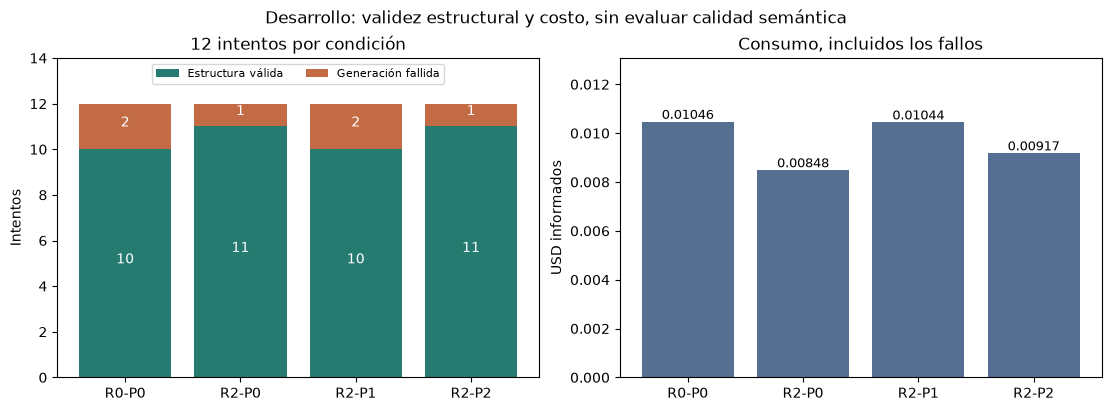

In [3]:
display(summary[["attempts", "accepted", "invalid", "acceptance_rate", "cost_usd"]].rename(columns={
    "attempts": "Intentos", "accepted": "Válidas", "invalid": "Fallos",
    "acceptance_rate": "Fracción válida", "cost_usd": "Consumo USD",
}))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
x = np.arange(len(summary))
axes[0].bar(x, summary["accepted"], color="#267b70", label="Estructura válida")
axes[0].bar(x, summary["invalid"], bottom=summary["accepted"], color="#c36b45", label="Generación fallida")
for i, row in enumerate(summary.itertuples()):
    axes[0].text(i, row.accepted / 2, str(row.accepted), ha="center", color="white")
    axes[0].text(i, row.accepted + row.invalid / 2, str(row.invalid), ha="center", color="white")
axes[0].set(xticks=x, xticklabels=summary.index, ylim=(0, 14), ylabel="Intentos", title="12 intentos por condición")
axes[0].legend(loc="upper center", ncol=2, fontsize=8)
costs = summary["cost_usd"].astype(float)
axes[1].bar(x, costs, color="#546f91")
for i, value in enumerate(costs):
    axes[1].text(i, value, f"{value:.5f}", ha="center", va="bottom", fontsize=9)
axes[1].set(xticks=x, xticklabels=summary.index, ylabel="USD informados",
            ylim=(0, max(costs) * 1.25), title="Consumo, incluidos los fallos")
fig.suptitle("Desarrollo: validez estructural y costo, sin evaluar calidad semántica")
figures["validez-y-consumo"] = fig
plt.show()

## 4. Fallos y pares disponibles

El mapa muestra todos los casos. La ausencia de una respuesta no prueba que la otra condición sea semánticamente superior. Para comparar puntuaciones emparejadas se necesitan dos respuestas válidas **y dos revisiones**, y debe declararse cuántos pares están disponibles.

El tópico 665 tiene un único texto distinto, «pésima app». Su dificultad y la de otros casos ambiguos deben permanecer visibles. No cambiamos las entradas después de observar los resultados.

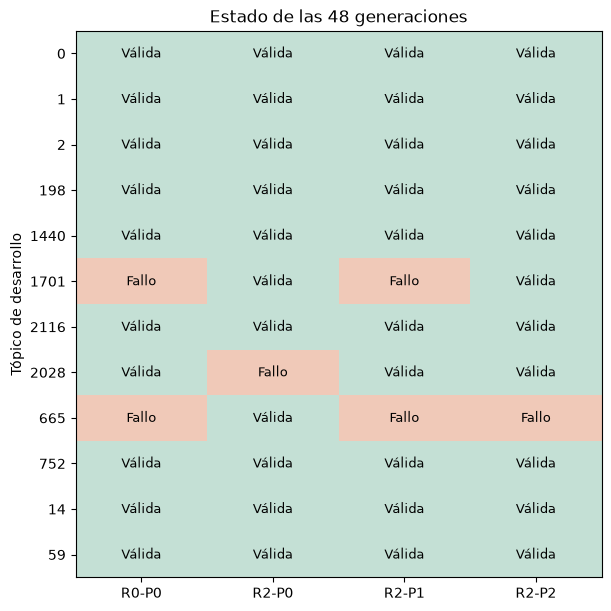

,topic_id,condition,error,finish_reason,completion_tokens,cost_usd,failure_reviewed
0,1701,R0-P0,incomplete_response,length,794,0.0022043,True
1,1701,R2-P1,incomplete_response,length,792,0.0022308,True
2,2028,R2-P0,incomplete_response,length,791,0.002195,True
3,665,R0-P0,incomplete_response,length,789,0.0021249,True
4,665,R2-P1,incomplete_response,length,785,0.002147,True
5,665,R2-P2,incomplete_response,length,796,0.0022108,True


,left,right,planned_pairs,available_pairs,missing_topic_ids
0,R0-P0,R2-P0,12,9,"[1701, 2028, 665]"
1,R2-P0,R2-P1,12,9,"[1701, 2028, 665]"
2,R2-P0,R2-P2,12,10,"[2028, 665]"


In [4]:
from matplotlib.colors import ListedColormap

conditions = list(summary.index)
topic_ids = list(cases)
validity = np.array([[int(results[f"{tid}-{c}"]["state"] == "accepted")
                      for c in conditions] for tid in topic_ids])
fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)
ax.imshow(validity, cmap=ListedColormap(["#f0c9b8", "#c4e0d5"]), vmin=0, vmax=1, aspect="auto")
for i in range(len(topic_ids)):
    for j in range(len(conditions)):
        ax.text(j, i, "Válida" if validity[i, j] else "Fallo", ha="center", va="center", fontsize=9)
ax.set(xticks=range(len(conditions)), xticklabels=conditions,
       yticks=range(len(topic_ids)), yticklabels=topic_ids,
       ylabel="Tópico de desarrollo", title="Estado de las 48 generaciones")
figures["estado-por-topico"] = fig
plt.show()
failures = rows.loc[rows["state"] != "accepted", [
    "topic_id", "condition", "error", "finish_reason", "completion_tokens", "cost_usd", "failure_reviewed"
]]
display(failures.reset_index(drop=True))
pair_coverage = pd.DataFrame(comparison["pair_coverage"])
display(pair_coverage)

## 5. Revisando las descripciones con sus reseñas

Lee primero los fragmentos enviados y después las cuatro respuestas. Usa **A–D** para registrar cada juicio. El orden cambia por tópico con semilla 42 y se conserva en la revisión. No constituye una evaluación completamente ciega: ya se han visto algunos resultados y los textos pueden revelar diferencias.

Cambia REVIEW_TOPIC para recorrer los 12 casos, o activa SHOW_ALL_TOPICS. Los textos se muestran completos. Los fallos son no evaluables y su salida incompleta puede desplegarse para diagnóstico.

Puedes retomar la revisión desde el archivo privado development-review.json. Se rechaza una revisión de otros recibos o con etiquetas alteradas.

In [5]:
REVIEW_FILE = DATA / "reports/topics/interpretation" / PROTOCOL_SHA256 / "development-review.json"
review = (json.loads(REVIEW_FILE.read_text()) if REVIEW_FILE.exists()
          else review_template(comparison, seed=42))
validate_review(review, comparison)
loaded_review_sha256 = fingerprint(review) if REVIEW_FILE.exists() else None

def paragraph(value):
    return '<p style="white-space:pre-wrap;overflow-wrap:anywhere">' + escape(str(value)) + '</p>'

def show_case(tid, reveal=False):
    case = cases[tid]
    html = f"<h2>Tópico {tid} · {case['size']} registros en el grupo</h2>"
    html += "<p>La revisión se limita a los fragmentos siguientes.</p>"
    for evidence in case["evidence"]:
        html += "<b>" + escape(evidence["label"]) + "</b>" + paragraph(evidence["text"])
        if evidence["truncated"]:
            html += "<i>Fragmento recortado por la política del estudio.</i>"
    for entry in (e for e in review["entries"] if e["topic_id"] == tid):
        row = results[entry["request_key"]]
        heading = entry["label"] + (f" · {row['condition']}" if reveal else "")
        html += '<section style="border:1px solid #999;padding:12px;margin:14px 0">'
        html += "<h3>Respuesta " + escape(heading) + "</h3>"
        if row["state"] != "accepted":
            html += paragraph("Generación fallida. No evaluable semánticamente. " + row["error"])
            html += "<details><summary>Salida incompleta para diagnóstico</summary>"
            html += paragraph(row["raw_content"]) + "</details>"
        else:
            html += "<b>" + escape(row["name"]) + "</b>"
            html += paragraph(row["description"])
            html += paragraph("Evaluación del modelo: " + row["assessment"])
            html += paragraph("Funcionalidad propuesta: " + str(row["proposed_feature"]))
            html += paragraph("Evidencia citada: " + ", ".join(row["supporting_evidence"]))
        html += "</section>"
    display(HTML(html))

REVIEW_TOPIC = 0
SHOW_ALL_TOPICS = False
for tid in (topic_ids if SHOW_ALL_TOPICS else [REVIEW_TOPIC]):
    show_case(tid)

## 6. Registrando la evaluación

Aplica la misma pauta a las 42 respuestas válidas. Los seis fallos quedan como no evaluables, sin puntuaciones. No penalices una incertidumbre bien explicada solo por no identificar una funcionalidad.

| Criterio | 0 | 1 | 2 |
| --- | --- | --- | --- |
| Funcionalidad respaldada | Inventa o contradice la evidencia | Es compatible, pero poco precisa | Identifica una capacidad respaldada o reconoce correctamente que no puede identificarla |
| Comportamiento fiel | Inventa una incidencia o una causa | Resume parcialmente | Describe fielmente lo observado, incluido un juicio positivo cuando corresponde |
| Utilidad | Induce una lectura equivocada | Ofrece una orientación general | Orienta la revisión del producto o explica con claridad por qué no es posible |
| Ambigüedad y citas | Fuerza una sola lectura o cita sin respaldo | Reconoce parte de la limitación | Expresa mezcla o insuficiencia cuando corresponde y respalda sus afirmaciones |

Marca además critical_error si inventa o contradice una funcionalidad, comportamiento o causa. Una etiqueta E1 existente no garantiza respaldo semántico. Cita los fragmentos que justifican tu revisión.

Añade registros a REVIEW_UPDATES siguiendo el ejemplo comentado, con autor, fecha, human o assisted, cuatro puntuaciones y explicación. No hay puntuaciones preasignadas. Activa SAVE_REVIEW para guardar y retomar. La exportación final también conserva una copia.

In [6]:
REVIEW_UPDATES = [
    # {
    #     "topic_id": 0, "label": "A",
    #     "scores": {"supported_feature": ..., "faithful_behavior": ...,
    #                "usefulness": ..., "ambiguity_and_citations": ...},
    #     "critical_error": ..., "evidence_labels": ["E1"],
    #     "note": "Explica el juicio y su respaldo.",
    #     "reviewer": "Nombre o identificador", "review_kind": "human",
    #     "reviewed_at": datetime.now(timezone.utc).isoformat(),
    # },
]
review = apply_review_updates(review, REVIEW_UPDATES, comparison)
SAVE_REVIEW = False
if SAVE_REVIEW:
    current = json.loads(REVIEW_FILE.read_text()) if REVIEW_FILE.exists() else None
    if (fingerprint(current) if current is not None else None) != loaded_review_sha256:
        raise ValueError("La revisión cambió en disco. Recarga antes de guardar.")
    REVIEW_FILE.parent.mkdir(parents=True, exist_ok=True)
    atomic_json(REVIEW_FILE, review)
    loaded_review_sha256 = fingerprint(review)
    print("Revisión guardada:", REVIEW_FILE)
display(pd.Series([e["status"] for e in review["entries"]]).value_counts().rename("Casos").to_frame())

,Casos
scored,42
unscorable,6


### Consultando las palabras y los prompts después de revisar

Activa REVEAL_CONDITIONS para ver la correspondencia de etiquetas, palabras clave y prompts exactos. Los pesos R0 y R2 no pertenecen a una escala común. Las reseñas siguen siendo la referencia para validar afirmaciones.

In [7]:
REVEAL_CONDITIONS = False
if REVEAL_CONDITIONS:
    display(pd.DataFrame([{k: e[k] for k in ("topic_id", "label", "request_key")}
                          for e in review["entries"]]))
    for representation, keywords in cases[REVIEW_TOPIC]["keywords"].items():
        display(HTML("<h4>" + escape(representation) + "</h4>" +
                     paragraph(", ".join(k["term"] for k in keywords))))
    for name, prompt in comparison["prompts"].items():
        display(HTML("<details><summary>" + escape(name + " · " + prompt["version"]) +
                     "</summary>" + paragraph(prompt["text"]) + "</details>"))
else:
    print("Correspondencia, palabras y prompts ocultos en esta vista.")

Correspondencia, palabras y prompts ocultos en esta vista.


## 7. Interpretando la revisión sin ocultar datos faltantes

Las puntuaciones no se completan con ceros ni se mezclan con fallos de generación. La tabla contiene únicamente revisiones registradas y distingue autoría humana y asistida. No calculamos un ganador automático ni una puntuación global.

Para elegir el prompt se prioriza ausencia de errores críticos observados, después funcionalidad, fidelidad y ambigüedad. La utilidad es complementaria. Ante resultados equivalentes, se conserva P0. Si la evidencia no alcanza para elegir, se documenta como inconclusa. El prompt se congela antes de abrir la reserva mediante un paso separado.

In [8]:
scored_rows = []
for entry in review["entries"]:
    if entry["status"] == "scored":
        scored_rows.append({
            "topic_id": entry["topic_id"], "condition": results[entry["request_key"]]["condition"],
            "reviewer": entry["reviewer"], "review_kind": entry["review_kind"],
            "critical_error": entry["critical_error"], **entry["scores"],
        })
scores = pd.DataFrame(scored_rows)
if scores.empty:
    print("Evaluación semántica pendiente. No hay puntuaciones ni selección de prompt.")
else:
    display(scores)
    display(scores.groupby(["condition", "review_kind"])[list(CRITERIA)].agg(["count", "mean"]))
    print("Medias descriptivas de los casos puntuados. Revisa cobertura, pares y errores críticos.")
scored_pairs = []
for pair in comparison["pair_coverage"]:
    for kind in ("human", "assisted"):
        sets = [{e["topic_id"] for e in review["entries"]
                 if e["status"] == "scored" and e["review_kind"] == kind
                 and results[e["request_key"]]["condition"] == condition}
                for condition in (pair["left"], pair["right"])]
        scored_pairs.append({"left": pair["left"], "right": pair["right"], "review_kind": kind,
                             "scored_pairs": len(sets[0] & sets[1]), "planned_pairs": len(cases)})
display(pd.DataFrame(scored_pairs))

,topic_id,condition,reviewer,review_kind,critical_error,ambiguity_and_citations,faithful_behavior,supported_feature,usefulness
0,0,R2-P1,Codex (asistente de IA),assisted,False,1,1,1,1
1,0,R2-P0,Codex (asistente de IA),assisted,False,1,1,1,1
2,0,R2-P2,Codex (asistente de IA),assisted,False,1,1,1,1
3,0,R0-P0,Codex (asistente de IA),assisted,False,1,1,1,1
4,1,R2-P2,Codex (asistente de IA),assisted,False,2,2,2,2
5,1,R2-P1,Codex (asistente de IA),assisted,False,1,1,2,1
6,1,R0-P0,Codex (asistente de IA),assisted,False,1,1,2,1
7,1,R2-P0,Codex (asistente de IA),assisted,False,1,1,2,1
8,2,R2-P0,Codex (asistente de IA),assisted,False,0,2,1,1
9,2,R2-P2,Codex (asistente de IA),assisted,False,2,2,2,2


supported_feature           faithful_behavior            \
                                  count      mean             count      mean   
condition review_kind                                                           
R0-P0     assisted                   10  1.500000                10  1.300000   
R2-P0     assisted                   11  1.545455                11  1.545455   
R2-P1     assisted                   10  1.500000                10  1.500000   
R2-P2     assisted                   11  1.454545                11  1.363636   

                      usefulness           ambiguity_and_citations            
                           count      mean                   count      mean  
condition review_kind                                                         
R0-P0     assisted            10  1.300000                      10  1.000000  
R2-P0     assisted            11  1.363636                      11  0.909091  
R2-P1     assisted            10  1.400000                      10  1.200000  
R2-P2     assisted            11  1.363636                      11  1.181818

Medias descriptivas de los casos puntuados. Revisa cobertura, pares y errores críticos.


,left,right,review_kind,scored_pairs,planned_pairs
0,R0-P0,R2-P0,human,0,12
1,R0-P0,R2-P0,assisted,9,12
2,R2-P0,R2-P1,human,0,12
3,R2-P0,R2-P1,assisted,9,12
4,R2-P0,R2-P2,human,0,12
5,R2-P0,R2-P2,assisted,10,12


## 8. Exportando evidencia para el artículo

Exportamos los resultados de la libreta para la elaboración del reporte. Los textos y la revisión quedan en archivos privados bajo data/.

In [9]:
export_root = Path(os.environ.get(
    "VOC_INTERPRETATION_EXPORT_ROOT", DATA / "reports/topics/interpretation"
))
folder = export_root / PROTOCOL_SHA256 / (
    datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid4().hex[:8]
)
folder.mkdir(parents=True, exist_ok=False)
summary.to_csv(folder / "resumen.csv")
rows.drop(columns=["raw_content", "tracking", "supporting_evidence"]).to_csv(
    folder / "solicitudes.csv", index=False
)
failures.to_csv(folder / "fallos.csv", index=False)
pair_coverage.to_csv(folder / "pares-disponibles.csv", index=False)
pd.DataFrame(scored_pairs).to_csv(folder / "pares-evaluados.csv", index=False)
if not scores.empty:
    scores.to_csv(folder / "puntuaciones.csv", index=False)
for name, data in {
    "comparacion-privada.json": comparison,
    "revision.json": review,
    "correspondencia-privada.json": [{k: e[k] for k in ("topic_id", "label", "request_key")}
                                    for e in review["entries"]],
}.items():
    (folder / name).write_bytes(canonical_json(data))
for name, fig in figures.items():
    fig.savefig(folder / (name + ".png"), dpi=180, bbox_inches="tight")
    fig.savefig(folder / (name + ".pdf"), bbox_inches="tight")
notebook = REPO / "reports/topics/resultados-de-interpretacion.ipynb"
manifest = {
    "schema_version": "voc-interpretation-notebook-export-v1",
    "created_at": datetime.now(timezone.utc).isoformat(),
    "protocol_sha256": PROTOCOL_SHA256,
    "source_sha256": comparison["source_sha256"],
    "receipts": comparison["receipts"],
    "review_sha256": fingerprint(review),
    "notebook_code_sha256": fingerprint([
        {"cell_type": c["cell_type"], "source": c["source"]}
        for c in json.loads(notebook.read_text())["cells"]
    ]),
    "population_scope": "12 development topics, 48 requests",
    "model_requests": 0, "reserve_opened": False,
    "files": {p.name: file_hash(p) for p in sorted(folder.iterdir()) if p.is_file()},
}
(folder / "manifest.json").write_bytes(canonical_json(manifest))
print("Evidencia exportada:", folder)

Evidencia exportada: /workspace/data/reports/topics/interpretation/59dd25185e6a4b02166e7558d78e90043ff87167d112ec3ab1d1f5f2c5c5c676/20261104T084924Z-4a146e81


## 10. Evaluación reservada de P0

Leemos las doce solicitudes reservadas de G3 + R2 + P0. El prompt se eligió antes de abrir estos casos. Las respuestas inválidas conservan su costo y no reciben puntuaciones semánticas. La revisión guardada es asistida, pendiente de validación humana. La aceptación exige cero errores críticos y al menos diez de doce casos con puntuación mínima de uno en las cuatro dimensiones. Esta sección no ejecuta modelos.


In [10]:
from voc_ml.topics.interpretation.comparison import read_reserve_results, evaluate_reserve

RESERVE_PROTOCOL = "aff54c808ba5f41087b99d9ff5908cdeee31c7d52712d976d4ec6d13cf33b6b9"
RESERVE_SOURCE = "45573e757dd683be22e958d20a1502928d5382c498e4369594d6dbaf5ef30259"
reserve_store = InterpretationStore(DATA / "topics/interpretation/reserve-execution")
reserve = read_reserve_results(parent=store, store=reserve_store, protocol_sha256=RESERVE_PROTOCOL)
assert reserve["source_sha256"] == RESERVE_SOURCE
reserve_review_file = DATA / "reports/topics/interpretation" / RESERVE_PROTOCOL / "reserve-review.json"
reserve_review = json.loads(reserve_review_file.read_text()) if reserve_review_file.exists() else review_template(reserve)
validate_review(reserve_review, reserve)
reserve_evaluation = evaluate_reserve(reserve_review, reserve)
display(pd.DataFrame(reserve["summaries"]))
display(pd.DataFrame([reserve_evaluation]))
print("La validez del JSON no demuestra fidelidad semántica. Autoría:", reserve_evaluation["review_kind"])


,condition,attempts,accepted,invalid,acceptance_rate,cost_usd,prompt_tokens,completion_tokens
0,R2-P0,12,7,5,0.583333,0.0146036,8612,4808


,protocol_sha256,source_sha256,review_sha256,state,review_kind,planned_cases,scored_cases,pending_cases,generation_failures,critical_errors,cases_all_criteria_ge_one,human_validation_pending,automatic_promotion
0,aff54c808ba5f41087b99d9ff5908cdeee31c7d52712d9...,45573e757dd683be22e958d20a1502928d5382c498e436...,0d8869c03e59c75ff6a556a13c1e75399348ea160e93a3...,criteria_not_met,assisted,12,7,0,5,1,5,True,False


La validez del JSON no demuestra fidelidad semántica. Autoría: assisted


### Evidencia, respuesta y justificación

Selecciona RESERVE_TOPIC para leer cada caso. Las puntuaciones se conservan aparte del protocolo. Los cinco fallos por longitud no se reemplazan ni se repiten. Los casos válidos muestran también la justificación de la revisión asistida.


In [11]:
RESERVE_TOPIC = 41
reserve_cases = {c["topic_id"]: c for c in reserve["cases"]}
reserve_rows = {r["topic_id"]: r for r in reserve["rows"]}
reserve_annotations = {e["topic_id"]: e for e in reserve_review["entries"]}
reserve_summary = []
for tid, row in reserve_rows.items():
    annotation = reserve_annotations[tid]
    reserve_summary.append({"topic_id": tid, "generation": row["state"], "assessment": row["assessment"],
                            "review": annotation["status"], "critical_error": annotation["critical_error"],
                            **annotation["scores"]})
display(pd.DataFrame(reserve_summary))
case, row, annotation = reserve_cases[RESERVE_TOPIC], reserve_rows[RESERVE_TOPIC], reserve_annotations[RESERVE_TOPIC]
html = f"<h3>Tópico {RESERVE_TOPIC}</h3>"
for e in case["evidence"]:
    html += "<b>" + escape(e["label"]) + "</b>" + paragraph(e["text"])
html += paragraph(row["name"]) + paragraph(row["description"])
html += paragraph("Estado de generación: " + row["state"])
html += paragraph("Clasificación: " + str(row["assessment"]))
html += paragraph("Evidencia citada: " + ", ".join(row["supporting_evidence"]))
html += paragraph("Revisión: " + annotation["note"])
html += paragraph("Autoría: " + str(annotation["review_kind"]))
display(HTML(html))


,topic_id,generation,assessment,review,critical_error,ambiguity_and_citations,faithful_behavior,supported_feature,usefulness
0,1634,accepted,unclear,scored,False,2.0,2.0,2.0,2.0
1,2132,accepted,single_feature,scored,False,1.0,1.0,1.0,1.0
2,1615,accepted,single_feature,scored,False,2.0,2.0,2.0,2.0
3,1578,invalid,None,unscorable,None,NaN,NaN,NaN,NaN
4,459,invalid,None,unscorable,None,NaN,NaN,NaN,NaN
5,974,invalid,None,unscorable,None,NaN,NaN,NaN,NaN
6,917,invalid,None,unscorable,None,NaN,NaN,NaN,NaN
7,975,invalid,None,unscorable,None,NaN,NaN,NaN,NaN
8,29,accepted,single_feature,scored,False,1.0,1.0,1.0,1.0
9,41,accepted,single_feature,scored,True,0.0,0.0,0.0,0.0


### Cobertura y criterio de aceptación

La figura mantiene doce casos como denominador. La barra de formato cuenta JSON válidos. La segunda distingue los casos que alcanzan el mínimo en cada dimensión y no convierte los fallos de generación en puntuaciones cero. El error crítico se informa por separado. Un resultado asistido no equivale a una evaluación humana independiente.


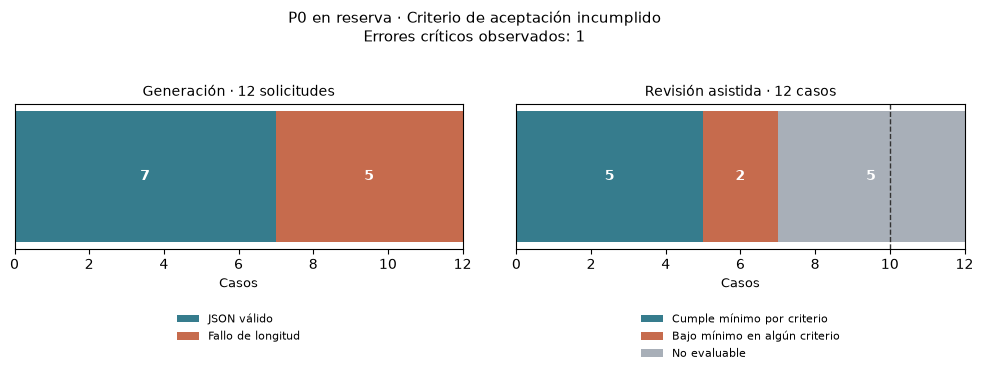

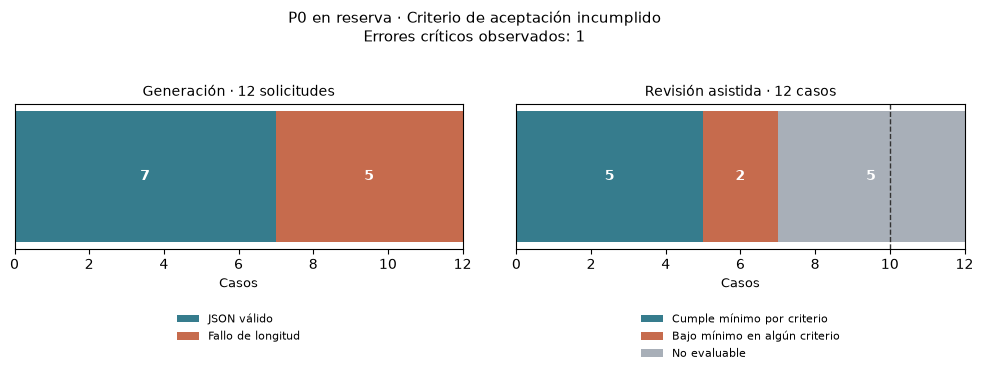

In [12]:
reserve_fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
accepted = reserve["summaries"][0]["accepted"]
failed = reserve_evaluation["generation_failures"]
qualified = reserve_evaluation["cases_all_criteria_ge_one"]
scored = reserve_evaluation["scored_cases"]
for ax, values, labels, title in [
    (axes[0], [accepted, failed], ["JSON válido", "Fallo de longitud"], "Generación · 12 solicitudes"),
    (axes[1], [qualified, scored-qualified, failed, reserve_evaluation["pending_cases"]],
     ["Cumple mínimo por criterio", "Bajo mínimo en algún criterio", "No evaluable", "Revisión pendiente"],
     "Revisión asistida · 12 casos"),
]:
    offset = 0
    for value, label, color in zip(values, labels, ["#367C8D", "#C66B4D", "#A8AFB8", "#E4C36C"]):
        if value:
            ax.barh([0], [value], left=offset, color=color, label=label)
            ax.text(offset+value/2, 0, str(value), ha="center", va="center", color="white", weight="bold")
        offset += value
    ax.set_xlim(0, 12); ax.set_xticks(range(0, 13, 2)); ax.set_yticks([])
    ax.set_title(title, fontsize=10); ax.set_xlabel("Casos", fontsize=9)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.38), frameon=False, fontsize=8)
axes[1].axvline(10, color="#333333", linestyle="--", linewidth=1)
outcome_label = {"criteria_not_met": "Criterio de aceptación incumplido", "criteria_met": "Criterio de aceptación cumplido", "review_pending": "Revisión pendiente"}[reserve_evaluation["state"]]
reserve_fig.suptitle(f"P0 en reserva · {outcome_label}\nErrores críticos observados: {reserve_evaluation['critical_errors']}", fontsize=11)
reserve_fig.subplots_adjust(left=0.04, right=0.99, bottom=0.35, top=0.73, wspace=0.12)
display(reserve_fig)


### Exportando evidencia de reserva

Exportamos los resultados de la libreta para la elaboración del reporte.


In [13]:
reserve_folder = export_root / RESERVE_PROTOCOL / (datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid4().hex[:8])
reserve_folder.mkdir(parents=True, exist_ok=False)
pd.DataFrame(reserve["summaries"]).to_csv(reserve_folder / "resumen.csv", index=False)
pd.DataFrame(reserve_summary).to_csv(reserve_folder / "puntuaciones.csv", index=False)
for name, value in {"comparacion-privada.json": reserve, "revision.json": reserve_review, "evaluacion.json": reserve_evaluation}.items():
    (reserve_folder / name).write_bytes(canonical_json(value))
for suffix in ("pdf", "png"):
    reserve_fig.savefig(reserve_folder / ("reserva-cobertura." + suffix), dpi=180, bbox_inches="tight")
reserve_manifest = {
    "schema_version": "voc-interpretation-reserve-notebook-export-v1",
    "created_at": datetime.now(timezone.utc).isoformat(), "protocol_sha256": RESERVE_PROTOCOL,
    "source_sha256": reserve["source_sha256"], "review_sha256": fingerprint(reserve_review),
    "notebook_code_sha256": fingerprint([{ "cell_type": c["cell_type"], "source": c["source"]} for c in json.loads(notebook.read_text())["cells"]]),
    "population_scope": "12 reserved topics, one R2/P0 request per topic", "review_kind": reserve_evaluation["review_kind"],
    "model_requests": 0, "files": {p.name: file_hash(p) for p in sorted(reserve_folder.iterdir()) if p.is_file()},
}
(reserve_folder / "manifest.json").write_bytes(canonical_json(reserve_manifest))
print("Evidencia de reserva exportada:", reserve_folder)


Evidencia de reserva exportada: /workspace/data/reports/topics/interpretation/aff54c808ba5f41087b99d9ff5908cdeee31c7d52712d976d4ec6d13cf33b6b9/20261104T084925Z-a9da821f


## 11. Comprobación del mecanismo homologado

Leemos los intentos nuevos del prompt fijo, si existen. Esta comprobación usa hasta seis reseñas por tópico y conserva el orden y el transporte del prototipo. Los casos conocidos no son una nueva reserva independiente. Una respuesta aceptada indica validez técnica; revisa su fidelidad leyendo las reseñas y la descripción completa.


In [14]:
from voc_ml.topics.interpretation.prototype import inspect as inspect_fixed
from voc_ml.topics.interpretation.ledger import InterpretationStore

fixed_root = DATA / "topics/interpretation/prototype-execution"
fixed = None
if not (fixed_root / "ledger.json").exists():
    print("Comprobación homologada pendiente. Esta libreta no ejecuta modelos.")
else:
    fixed_store = InterpretationStore(fixed_root)
    fixed = inspect_fixed(fixed_store)
    fixed_cases = {str(c["topic_id"]): c for c in fixed_store.load()["protocol"]["cases"]}
    display(pd.DataFrame([
        {"tópico": key, "estado": a["state"], "costo_usd": a["charged_usd"]}
        for key, a in fixed["attempts"].items()
    ]))
    for key, attempt in fixed["attempts"].items():
        print("Tópico", key)
        for e in fixed_cases[key]["evidence"]:
            print(e["label"], e["text"])
        print(json.dumps(attempt["outcome"], ensure_ascii=False, indent=2))


,tópico,estado,costo_usd
0,59,accepted,0.0007051
1,975,accepted,0.0005545


Tópico 59
E1 no me gusta mucho, ya que no me da notificaciones y las tengo activas, cuando me hacen una transferencia no me notifica de dicha transferencia, y cuando yo hago un pago, tampoco me notifica y eso es incómodo, ya que tengo que estar checando que realmente se vea reflejado algún movimiento ya que no hay notificaciones
E2 Tienen muchas áreas de oportunidad para mejorar como sus notificaciones nunca me llegan mis notificaciones y cabe recalcar que ya fui al banco dos veces y nada que se activen solo me llegan sus estúpidas publicidades pero si hago retiros o transferencias o depósitos no se me notifica más todo mal hecho
E3 todo está perfecto solo que cuando me cae algún depósito no me notifica solo cuando yo hago movimientos y eso me quita mucho tiempo estar checando si tengo transferencia o no ,,por más que le he movido no me llega esa notificación y quisiera saber cómo le ago para que aparezca
E4 No recibo las notificaciones de transferencias la
E5 No me llega notificación 

### Exportando la comprobación

Exportamos los resultados de la libreta para la elaboración del reporte.


In [15]:
if fixed is not None:
    fixed_folder = export_root / "prototype" / (datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid4().hex[:8])
    fixed_folder.mkdir(parents=True, exist_ok=False)
    fixed_artifact = {"kind": "prototype_mechanism_check", "results": fixed, "cases": fixed_cases, "model_requests": 0}
    (fixed_folder / "results.json").write_text(json.dumps(fixed_artifact, ensure_ascii=False, indent=2))
    print("Comprobación exportada:", fixed_folder)


Comprobación exportada: /workspace/data/reports/topics/interpretation/prototype/20261104T084925Z-f6e17016
